# ML Experiment Results

Generic template notebook: loads every experiment JSON for one greenhouse +
target combination, builds summary tables and plots.

To create one of the four target notebooks (Alava/temperature,
Alava/rel_humidity, Cartagena/temperature, Cartagena/rel_humidity), copy
this notebook and only change `GREENHOUSE` and `TARGET` in the Config cell
below — everything else adapts automatically.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110


## 1. Configuration

In [2]:
# Greenhouse and target this notebook analyzes.
# GREENHOUSE: "alava" or "cartagena"
# TARGET:     "temperature" or "rel_humidity"
GREENHOUSE = "cartagena"
TARGET = "rel_humidity"

# Base results folder for this greenhouse (one subfolder per model:
# lstm/, gru/, cnn_lstm/, dlinear/, nlinear/, patchtst/, itransformer/).
RESULTS_DIR = Path(f"../results/experiments/{GREENHOUSE}")

# Glob pattern: picks up every model's JSON for the chosen target, e.g.
# results/experiments/alava/lstm/temperature/01_lstm_alava_temp.json
PATTERN = f"*/{TARGET}/*.json"


## 2. Load data

In [3]:
def experiment_name(path: Path) -> str:
    """Experiment name derived from the file name.

    By default uses the file name as-is (without extension). If your
    files include a repetition/seed suffix you want to ignore when
    grouping (e.g. 'my_experiment_seed3.json'), adjust the regex here,
    for example:
        return re.sub(r"_seed\d+$", "", path.stem)
    """
    return path.stem


def load_results(directory: Path, pattern: str = "*.json"):
    """Loads every result JSON into a list of dicts, adding file/experiment
    metadata.

    Supports two file formats:
    - A single results dict per file: {..., "metrics": {...}}
    - A list of results dicts per file: [{...}, {...}, ...]
      (each list element is treated as a distinct repetition/run of the
      same file, and numbered automatically). This is the normal case
      here: each experiment script appends one entry per run to its JSON,
      so a script run 3 times produces a 3-element list.
    """
    files = sorted(Path(directory).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No '{pattern}' files found in {directory}")

    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)

        # Normalize to a list of dicts, however the file is shaped
        if isinstance(content, dict):
            items = [content]
        elif isinstance(content, list):
            items = content
        else:
            raise ValueError(f"Unexpected format in {f.name}: expected dict or list, "
                              f"got {type(content)}")

        for i, d in enumerate(items):
            if not isinstance(d, dict):
                raise ValueError(f"Item {i} of {f.name} is not a dict (it's {type(d)})")
            d = dict(d)  # copy so we don't mutate the original
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = experiment_name(f)
            data.append(d)
    return data


results = load_results(RESULTS_DIR, PATTERN)
print(f"Loaded {len(results)} result files, "
      f"corresponding to {len(set(d['_experiment'] for d in results))} distinct experiment(s).")


Loaded 35 result files, corresponding to 7 distinct experiment(s).


<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
C:\Users\jclps\AppData\Local\Temp\ipykernel_24072\1520848580.py:8: SyntaxWarning: invalid escape sequence '\d'
  return re.sub(r"_seed\d+$", "", path.stem)


## 3. Building the DataFrames

In [4]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"]["per_horizon"].items():
            row = {
                "experiment": d["_experiment"],
                "file": d["_file"],
                "horizon": int(h_key.split("_")[1]),
            }
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_month_df(data):
    rows = []
    for d in data:
        for month, metrics in d["metrics"].get("per_month", {}).items():
            row = {"experiment": d["_experiment"], "file": d["_file"], "month": month}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_day_night_df(data):
    rows = []
    for d in data:
        for period in ("day", "night"):
            metrics = d["metrics"].get(period)
            if metrics:
                row = {"experiment": d["_experiment"], "file": d["_file"], "period": period}
                row.update(metrics)
                rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(results)
df_horizon = build_horizon_df(results)
df_month = build_month_df(results)
df_day_night = build_day_night_df(results)

df_global.head()


,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,06_cnn_lstm_cartagena_hum,06_cnn_lstm_cartagena_hum.json[0],0.524,52.282,7.231,4.028,5.096,-0.002,0.051
1,06_cnn_lstm_cartagena_hum,06_cnn_lstm_cartagena_hum.json[1],0.516,53.131,7.289,3.428,4.576,0.009,0.046
2,06_cnn_lstm_cartagena_hum,06_cnn_lstm_cartagena_hum.json[2],0.552,49.171,7.012,3.516,4.565,0.004,0.046
3,06_cnn_lstm_cartagena_hum,06_cnn_lstm_cartagena_hum.json[3],0.542,50.368,7.097,3.878,4.906,-0.001,0.049
4,06_cnn_lstm_cartagena_hum,06_cnn_lstm_cartagena_hum.json[4],0.544,50.097,7.078,3.827,4.856,-0.000,0.049


## 4. Global metrics table (mean ± std per experiment)

In [5]:
GLOBAL_METRICS = ["r2", "mse", "rmse", "mae", "mape"]  #, "relative_error", "relative_error_abs"]

global_table = (
    df_global
    .groupby("experiment")[GLOBAL_METRICS]
    .agg(["mean", "std"])
    .round(4)
)

# Flatten the multi-index columns, e.g. ('r2', 'mean') -> 'r2_mean'
global_table.columns = [f"{metric}_{stat}" for metric, stat in global_table.columns]
global_table = global_table.sort_index()
global_table


,r2_mean,r2_std,mse_mean,mse_std,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,mape_std
experiment,,,,,,,,,,
02_lstm_cartagena_hum,0.584,0.011,45.686,1.236,6.759,0.091,3.688,0.241,4.670,0.248
04_gru_cartagena_hum,0.579,0.008,46.267,0.873,6.802,0.064,3.718,0.162,4.655,0.155
06_cnn_lstm_cartagena_hum,0.536,0.015,51.010,1.639,7.141,0.115,3.735,0.254,4.800,0.228
07_dlinear_cartagena,0.815,0.003,20.382,0.335,4.515,0.037,1.722,0.124,2.398,0.124
08_nlinear_cartagena,0.816,0.003,20.272,0.322,4.502,0.036,1.655,0.008,2.299,0.009
09_patchtst_cartagena,0.871,0.001,14.312,0.136,3.783,0.018,1.725,0.083,2.256,0.076
10_itransformer_cartagena,0.867,0.002,14.703,0.190,3.834,0.025,1.621,0.072,2.201,0.057


### Compact 'mean ± std' version, easier to read

In [6]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out.sort_index()


compact_global_table = mean_std_table(df_global, GLOBAL_METRICS, ["experiment"])
compact_global_table


,r2,mse,rmse,mae,mape
experiment,,,,,
02_lstm_cartagena_hum,0.584 ± 0.011,45.686 ± 1.236,6.759 ± 0.092,3.688 ± 0.241,4.670 ± 0.248
04_gru_cartagena_hum,0.579 ± 0.008,46.267 ± 0.873,6.802 ± 0.064,3.718 ± 0.162,4.655 ± 0.155
06_cnn_lstm_cartagena_hum,0.536 ± 0.015,51.010 ± 1.639,7.141 ± 0.115,3.735 ± 0.254,4.800 ± 0.228
07_dlinear_cartagena,0.815 ± 0.003,20.382 ± 0.335,4.515 ± 0.037,1.722 ± 0.124,2.398 ± 0.124
08_nlinear_cartagena,0.816 ± 0.003,20.272 ± 0.322,4.502 ± 0.036,1.655 ± 0.008,2.299 ± 0.009
09_patchtst_cartagena,0.871 ± 0.001,14.312 ± 0.136,3.783 ± 0.018,1.725 ± 0.083,2.256 ± 0.076
10_itransformer_cartagena,0.866 ± 0.002,14.703 ± 0.190,3.834 ± 0.025,1.621 ± 0.072,2.201 ± 0.057


In [7]:
compact_global_table.to_latex()


'\\begin{tabular}{llllll}\n\\toprule\n & r2 & mse & rmse & mae & mape \\\\\nexperiment &  &  &  &  &  \\\\\n\\midrule\n02_lstm_cartagena_hum & 0.584 ± 0.011 & 45.686 ± 1.236 & 6.759 ± 0.092 & 3.688 ± 0.241 & 4.670 ± 0.248 \\\\\n04_gru_cartagena_hum & 0.579 ± 0.008 & 46.267 ± 0.873 & 6.802 ± 0.064 & 3.718 ± 0.162 & 4.655 ± 0.155 \\\\\n06_cnn_lstm_cartagena_hum & 0.536 ± 0.015 & 51.010 ± 1.639 & 7.141 ± 0.115 & 3.735 ± 0.254 & 4.800 ± 0.228 \\\\\n07_dlinear_cartagena & 0.815 ± 0.003 & 20.382 ± 0.335 & 4.515 ± 0.037 & 1.722 ± 0.124 & 2.398 ± 0.124 \\\\\n08_nlinear_cartagena & 0.816 ± 0.003 & 20.272 ± 0.322 & 4.502 ± 0.036 & 1.655 ± 0.008 & 2.299 ± 0.009 \\\\\n09_patchtst_cartagena & 0.871 ± 0.001 & 14.312 ± 0.136 & 3.783 ± 0.018 & 1.725 ± 0.083 & 2.256 ± 0.076 \\\\\n10_itransformer_cartagena & 0.866 ± 0.002 & 14.703 ± 0.190 & 3.834 ± 0.025 & 1.621 ± 0.072 & 2.201 ± 0.057 \\\\\n\\bottomrule\n\\end{tabular}\n'

## 5. Metrics table by month and by day/night

In [8]:
MONTH_METRICS = ["r2", "mse", "rmse", "mae", "mape"]

month_table = mean_std_table(df_month, MONTH_METRICS, ["experiment", "month"])
month_table


r2               mse  \
experiment                month                                       
02_lstm_cartagena_hum     2025-07  -2.165 ± 0.814  151.429 ± 38.927   
                          2025-08  -4.838 ± 0.670    26.514 ± 3.041   
                          2025-09  -3.755 ± 0.722     8.167 ± 1.241   
                          2025-10  -1.921 ± 0.442     9.199 ± 1.393   
                          2025-11  -6.391 ± 1.111     8.605 ± 1.294   
...                                           ...               ...   
10_itransformer_cartagena 2025-11   0.006 ± 0.113     1.157 ± 0.131   
                          2025-12   0.903 ± 0.007    26.692 ± 1.798   
                          2026-01   0.816 ± 0.002    32.013 ± 0.353   
                          2026-02   0.840 ± 0.008    30.824 ± 1.567   
                          2026-03   0.476 ± 0.110    17.194 ± 3.614   

                                             rmse            mae  \
experiment                month                                    
02_lstm_cartagena_hum     2025-07  12.210 ± 1.714  5.686 ± 0.527   
                          2025-08   5.142 ± 0.304  2.869 ± 0.267   
                          2025-09   2.851 ± 0.219  2.332 ± 0.288   
                          2025-10   3.026 ± 0.229  2.322 ± 0.299   
                          2025-11   2.927 ± 0.223  2.380 ± 0.284   
...                                           ...            ...   
10_itransformer_cartagena 2025-11   1.074 ± 0.061  0.616 ± 0.074   
                          2025-12   5.164 ± 0.171  2.132 ± 0.069   
                          2026-01   5.658 ± 0.031  3.108 ± 0.054   
                          2026-02   5.550 ± 0.142  3.286 ± 0.051   
                          2026-03   4.128 ± 0.442  2.295 ± 0.116   

                                            mape  
experiment                month                   
02_lstm_cartagena_hum     2025-07  6.309 ± 0.610  
                          2025-08  2.903 ± 0.267  
                          2025-09  2.348 ± 0.288  
                          2025-10  2.367 ± 0.298  
                          2025-11  2.390 ± 0.284  
...                                          ...  
10_itransformer_cartagena 2025-11  0.627 ± 0.075  
                          2025-12  3.913 ± 0.161  
                          2026-01  4.084 ± 0.068  
                          2026-02  4.521 ± 0.058  
                          2026-03  2.412 ± 0.121  

[62 rows x 5 columns]

In [9]:
DAY_NIGHT_METRICS = ["r2", "mse", "rmse", "mae", "mape", "relative_error", "relative_error_abs"]

day_night_table = mean_std_table(df_day_night, DAY_NIGHT_METRICS, ["experiment", "period"])
day_night_table


r2             mse  \
experiment                period                                  
02_lstm_cartagena_hum     day     0.548 ± 0.006  60.833 ± 0.750   
                          night   0.622 ± 0.021  32.991 ± 1.840   
04_gru_cartagena_hum      day     0.550 ± 0.003  60.555 ± 0.358   
                          night   0.607 ± 0.016  34.293 ± 1.437   
06_cnn_lstm_cartagena_hum day     0.530 ± 0.011  63.228 ± 1.464   
                          night   0.533 ± 0.023  40.770 ± 2.032   
07_dlinear_cartagena      day     0.826 ± 0.003  23.461 ± 0.383   
                          night   0.797 ± 0.003  17.810 ± 0.301   
08_nlinear_cartagena      day     0.829 ± 0.002  23.067 ± 0.291   
                          night   0.795 ± 0.004  17.936 ± 0.382   
09_patchtst_cartagena     day     0.862 ± 0.004  18.763 ± 0.558   
                          night   0.879 ± 0.005  10.613 ± 0.466   
10_itransformer_cartagena day     0.866 ± 0.005  18.096 ± 0.621   
                          night   0.864 ± 0.007  11.823 ± 0.667   

                                           rmse            mae           mape  \
experiment                period                                                
02_lstm_cartagena_hum     day     7.799 ± 0.048  4.202 ± 0.188  5.470 ± 0.190   
                          night   5.742 ± 0.160  3.257 ± 0.287  4.000 ± 0.298   
04_gru_cartagena_hum      day     7.782 ± 0.023  4.236 ± 0.131  5.466 ± 0.120   
                          night   5.855 ± 0.122  3.283 ± 0.189  3.976 ± 0.184   
06_cnn_lstm_cartagena_hum day     7.951 ± 0.091  4.239 ± 0.201  5.551 ± 0.175   
                          night   6.384 ± 0.159  3.313 ± 0.298  4.170 ± 0.271   
07_dlinear_cartagena      day     4.844 ± 0.039  2.192 ± 0.102  2.962 ± 0.104   
                          night   4.220 ± 0.035  1.329 ± 0.142  1.926 ± 0.140   
08_nlinear_cartagena      day     4.803 ± 0.030  2.146 ± 0.019  2.880 ± 0.020   
                          night   4.235 ± 0.045  1.244 ± 0.017  1.813 ± 0.012   
09_patchtst_cartagena     day     4.331 ± 0.065  2.139 ± 0.048  2.782 ± 0.054   
                          night   3.257 ± 0.071  1.382 ± 0.123  1.820 ± 0.122   
10_itransformer_cartagena day     4.253 ± 0.073  2.029 ± 0.059  2.707 ± 0.065   
                          night   3.437 ± 0.097  1.276 ± 0.133  1.773 ± 0.128   

                                  relative_error relative_error_abs  
experiment                period                                     
02_lstm_cartagena_hum     day      0.014 ± 0.003      0.055 ± 0.002  
                          night   -0.012 ± 0.003      0.040 ± 0.003  
04_gru_cartagena_hum      day      0.013 ± 0.002      0.055 ± 0.001  
                          night   -0.013 ± 0.002      0.040 ± 0.002  
06_cnn_lstm_cartagena_hum day      0.015 ± 0.005      0.056 ± 0.002  
                          night   -0.010 ± 0.005      0.042 ± 0.003  
07_dlinear_cartagena      day      0.012 ± 0.001      0.030 ± 0.001  
                          night    0.004 ± 0.001      0.019 ± 0.001  
08_nlinear_cartagena      day      0.010 ± 0.001      0.029 ± 0.000  
                          night    0.002 ± 0.000      0.018 ± 0.000  
09_patchtst_cartagena     day      0.011 ± 0.006      0.028 ± 0.001  
                          night    0.004 ± 0.004      0.018 ± 0.001  
10_itransformer_cartagena day      0.011 ± 0.003      0.027 ± 0.001  
                          night    0.008 ± 0.003      0.018 ± 0.001

## 6. Metric evolution across the prediction horizon

`plot_metric_by_horizon` plots a single metric for one or more experiments.
If an experiment has several repetitions (same `experiment`, different
files), the mean is drawn together with a shaded band of ± 1 standard
deviation.

The following cell (`plot_all_metrics_by_horizon`) reuses the same logic to
draw **every metric at once**, as a grid of subplots, so a single cell
produces the full picture instead of one plot per cell.


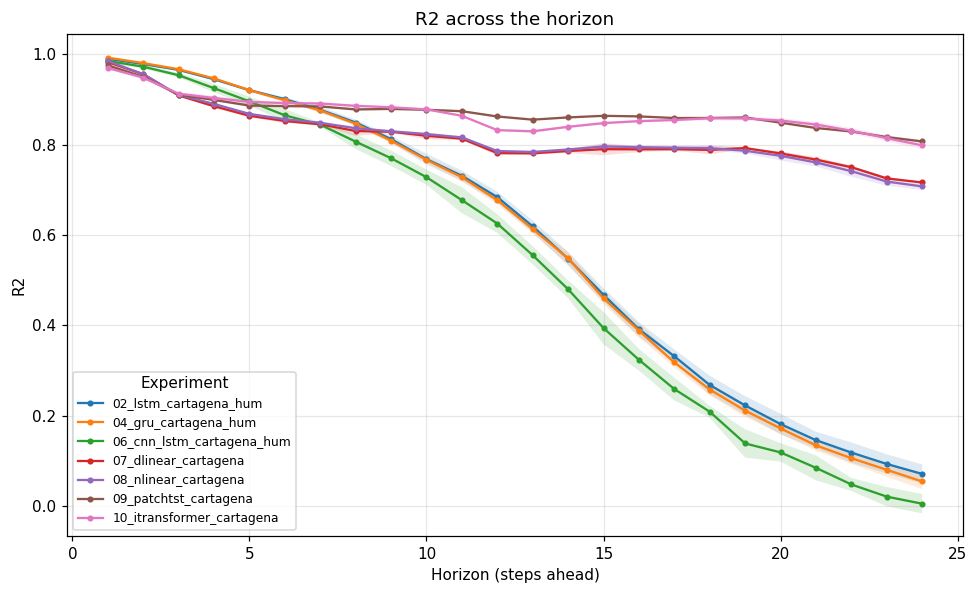

In [10]:
def plot_metric_by_horizon(df_horizon, experiments=None, metric="r2", ax=None,
                            figsize=(9, 5.5), title=None):
    """Plots the evolution of one metric (default r2) across the prediction
    horizon, for one or more experiments.

    Parameters
    ----------
    df_horizon : DataFrame returned by build_horizon_df
    experiments : str, list of str, or None (None = every available experiment)
    metric : metric column name to plot ('r2', 'mae', 'rmse', 'mape', ...)
    """
    if experiments is None:
        experiments = sorted(df_horizon["experiment"].unique())
    elif isinstance(experiments, str):
        experiments = [experiments]

    owns_figure = ax is None
    if owns_figure:
        fig, ax = plt.subplots(figsize=figsize)

    for experiment in experiments:
        subset = df_horizon[df_horizon["experiment"] == experiment]
        agg = subset.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=experiment)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    ax.set_xlabel("Horizon (steps ahead)")
    ax.set_ylabel(metric.upper() if metric in ("r2", "mae", "mse", "rmse") else metric)
    ax.set_title(title or f"{metric.upper()} across the horizon")
    ax.grid(alpha=0.3)
    ax.legend(title="Experiment", fontsize=8)
    if owns_figure:
        plt.tight_layout()
    return ax


plot_metric_by_horizon(df_horizon)
plt.show()


### All metrics at once

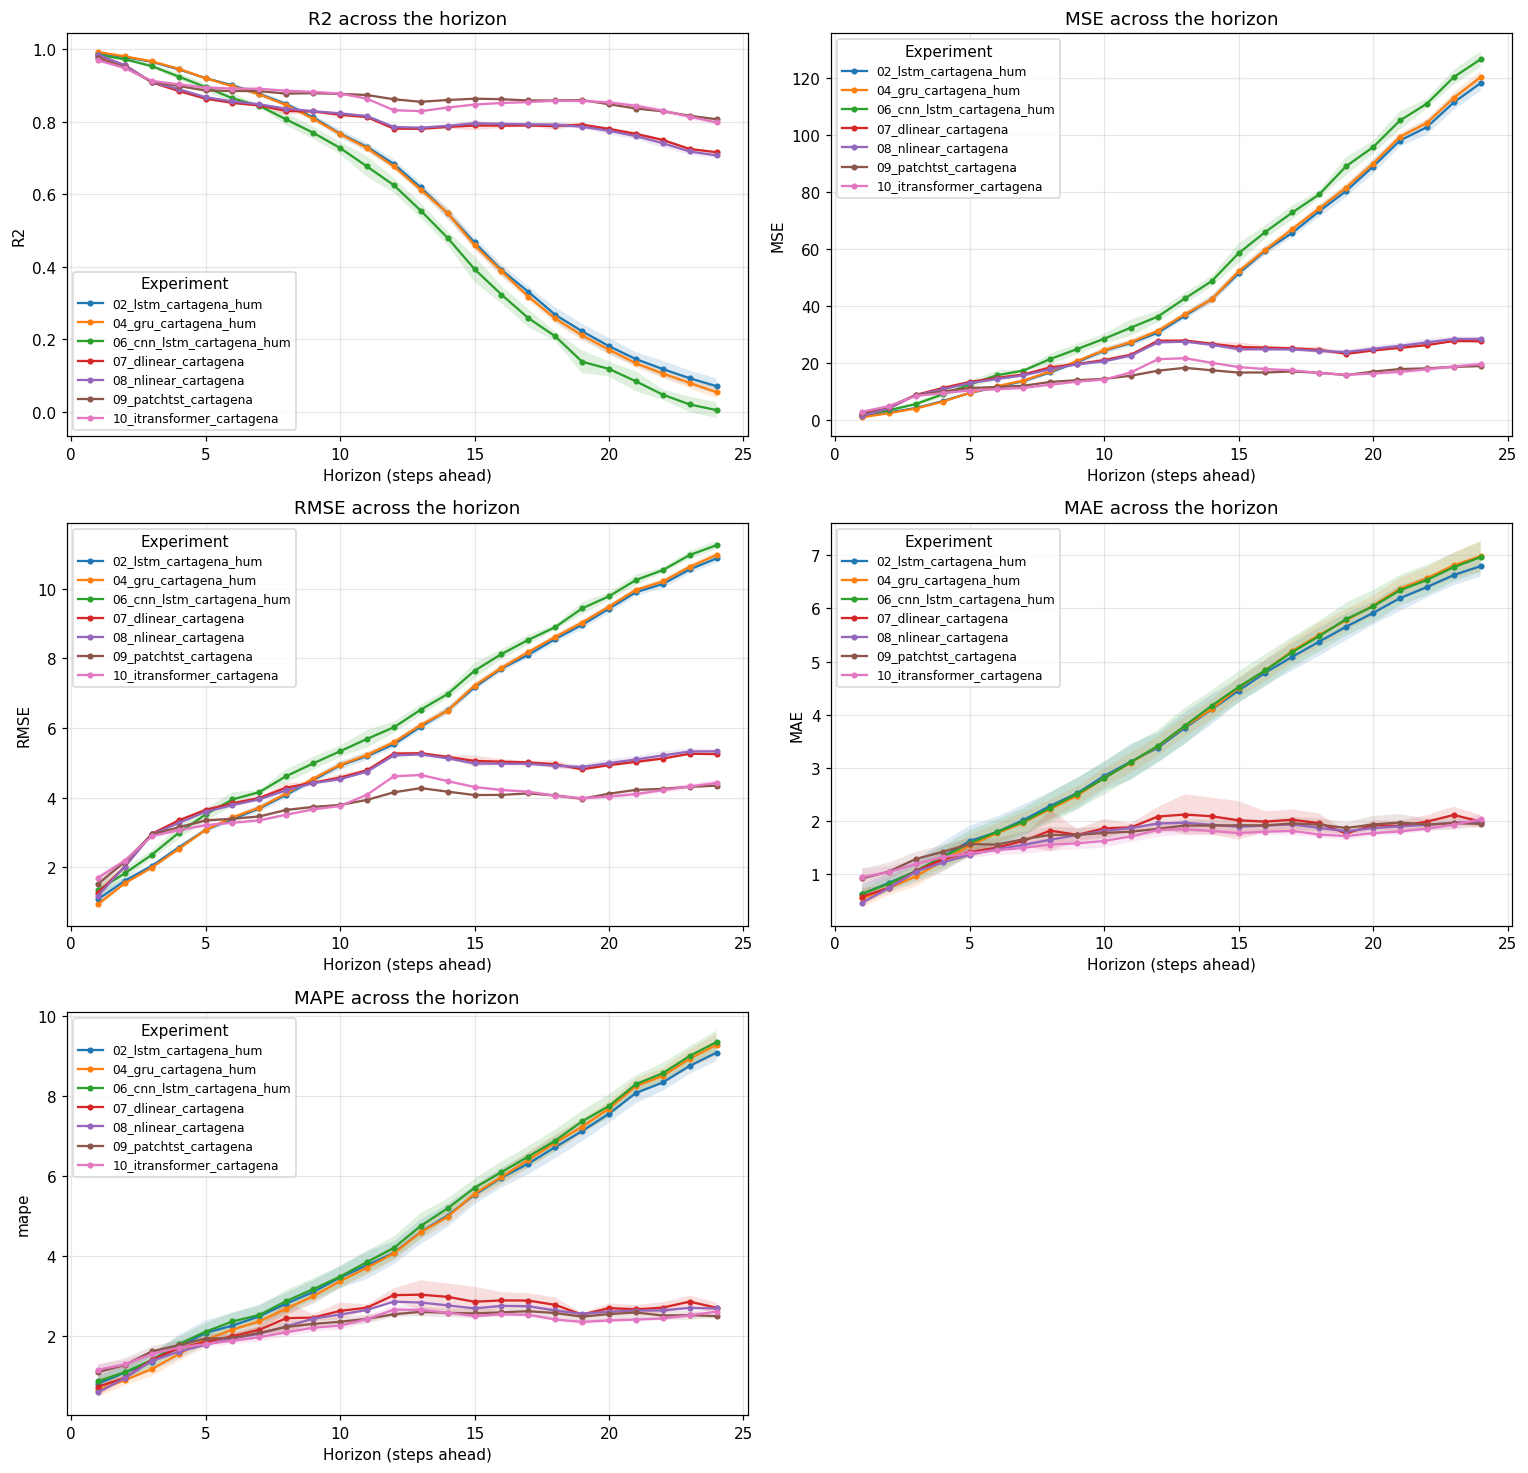

In [11]:
def plot_all_metrics_by_horizon(df_horizon, experiments=None,
                                 metrics=GLOBAL_METRICS, ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric (all of GLOBAL_METRICS by default), each
    showing every experiment, in a single figure - the one-cell replacement
    for calling plot_metric_by_horizon once per metric.
    """
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_by_horizon(df_horizon, experiments=experiments, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_all_metrics_by_horizon(df_horizon)
plt.show()
